
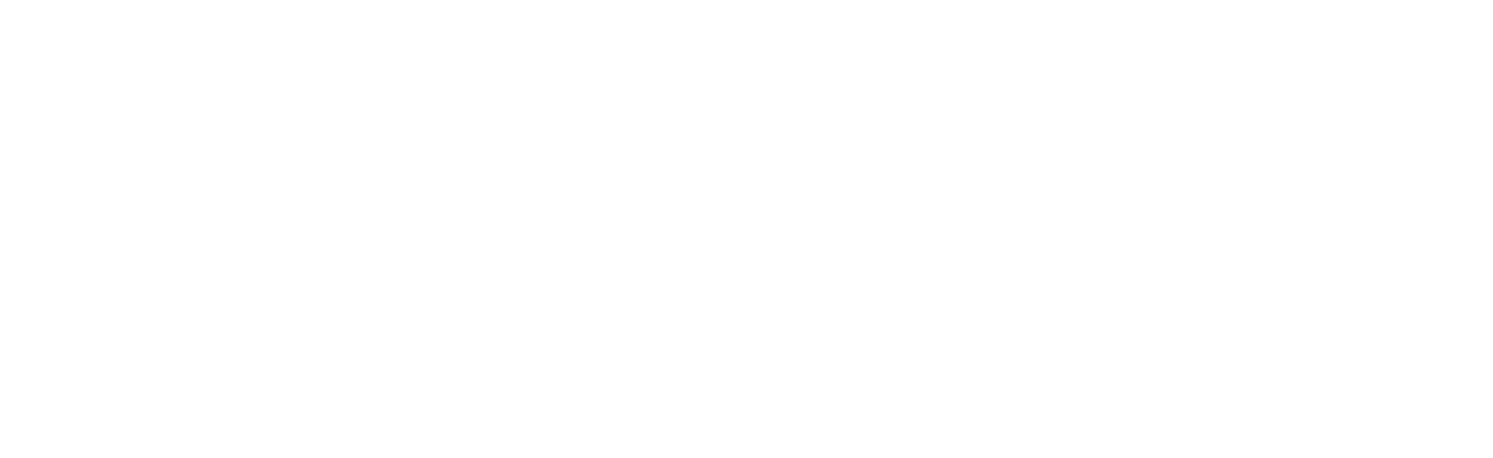

Output()

In [1]:
# ============ TABLEAU DE BORD DE PILOTAGE – SIMPLON SOLUTION (version une seule cellule) ============
# Installation (une fois, dans une autre cellule) : !pip install pandas plotly ipywidgets openpyxl anywidget
import warnings
warnings.filterwarnings("ignore")


# ======================================================================
# 1. CONFIGURATION
# ======================================================================
from pathlib import Path

LOGO = "logo_simplon.png"          # logo Simplon Solutions (version blanche, sur fond bleu foncé)

# Fichiers exportés depuis vos Google Sheets (CSV ou .xlsx)
FICHIER_RH      = "Volet RH & Effectifs.csv"
FICHIER_PROJETS = "SUIVI PROJET.csv"      # onglet « SUIVI PROJET » ou « projet »
FICHIER_AO      = "APPEL D'OFFRES.csv"
FICHIER_PLUGINS = "PLUGINS.csv"

# --- Source DYNAMIQUE : Google Sheets (lecture en direct) ---
# Dans chaque Google Sheet : Partager > « Tous les utilisateurs disposant du lien » > Lecteur.
# Collez ici le lien complet (ou seulement l'identifiant) de chaque fichier.
SHEET_PILOTAGE = "https://docs.google.com/spreadsheets/d/1sPeiBYLY2WJAlENyLfsU9zcj-nK8FTRqd9H926tsRSA/edit?gid=0#gid=0"   # fichier « Pilotage – Simplon Solution » (onglet RH & Effectifs)
SHEET_SUIVI    = "https://docs.google.com/spreadsheets/d/18sZppjkDXyrn2eXMWqTH05QWwdyqab2IFYMTngyDYSU/edit?gid=772463690#gid=772463690"   # fichier contenant l'onglet « SUIVI PROJET » (ex. « SUIVI PROJET SS »)
SHEET_AO       = "https://docs.google.com/spreadsheets/d/18sZppjkDXyrn2eXMWqTH05QWwdyqab2IFYMTngyDYSU/edit?gid=1826812305#gid=1826812305"   # fichier contenant l'onglet « APPEL D'OFFRES » ; laissez vide s'il est dans le même fichier que SUIVI PROJET

ONGLET_RH      = "Volet RH & Effectifs"
ONGLET_PROJETS = "SUIVI PROJET"      # ou "projet"
ONGLET_AO      = "APPEL D'OFFRES"
ONGLET_PLUGINS = "PLUGINS"
SHEET_PLUGINS  = ""                 # vide = même fichier que SUIVI PROJET

ALERTE_JOURS = 30                    # alerte plugins : échéance à moins de N jours
ACTUALISATION_AUTO_SECONDES = 60     # délai de l'actualisation automatique (case « Auto »)

# Charte graphique Simplon : bleu foncé (principal), rouge (accent), bleu, vert d'eau, gris, blanc
BLEU_FONCE = "#00313C"  # « gris Simplon » de la charte (bleu foncé) : couleur principale
ROUGE = "#E40046"       # rouge Simplon : accent (liseré, cartes, 2e couleur des graphiques)
BLANC = "#FFFFFF"
GRIS_CLAIR = "#CCD6D8"  # nuance claire du Gris Simplon #00313C (80 % de blanc)
GRIS  = "#00313C"       # Gris Simplon (textes)
ORANGE = "#FF8674"      # orange : touche de couleur (3e part des camemberts, barre sélectionnée, valeurs des barres)
PALETTE = [BLEU_FONCE, ROUGE, ORANGE, "#0072CE", "#64CCC9", "#8CA2A7", GRIS_CLAIR]  # couleurs de la charte Simplon 2024 + nuances du Gris Simplon


# ======================================================================
# 2. CHARGEMENT ET NETTOYAGE DES DONNÉES
# ======================================================================
import base64, re
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as W
from IPython.display import display, HTML, clear_output

pd.options.display.max_columns = 50

def lire(fichier):
    p = Path(fichier)
    if not p.exists():
        return None
    if p.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(p)
    for sep in (",", ";", "\t"):
        try:
            df = pd.read_csv(p, sep=sep, encoding="utf-8")
            if df.shape[1] > 2:
                return df
        except Exception:
            pass
    return pd.read_csv(p, sep=None, engine="python")

def norm(c):
    c = str(c).strip().lower()
    c = (c.replace("é","e").replace("è","e").replace("ê","e").replace("à","a")
           .replace("ç","c").replace("'","").replace("\n"," "))
    return re.sub(r"\s+", " ", c)

def renommer(df, mapping):
    """Renomme les colonnes selon des mots-clés (insensible à la casse/accents)."""
    out = {}
    for col in df.columns:
        n = norm(col)
        for cible, mots in mapping.items():
            if cible not in out.values() and any(m in n for m in mots):
                out[col] = cible
                break
    return df.rename(columns=out)

# --- Données de démonstration (utilisées seulement si les fichiers sont absents) ---
def demo_rh():
    return pd.DataFrame({
        "Prenom": list("ABCDEFGHIJ"), "Nom": [f"Nom{i}" for i in range(10)],
        "Role": ["Dev Web","Dev Web","Data","Designer","Chef de projet","Dev Mobile","Data","Dev Web","Designer","Support"],
        "Statut": ["CDI","CDD","Stagiaire","CDI","CDI","Alternant","CDD","CDI","Stagiaire","CDI"],
        "Fin contrat": pd.to_datetime(["2027-03-01","2026-12-15","2026-12-31","2027-06-30","2028-01-01",
                                       "2027-08-31","2026-11-30","2027-02-28","2026-12-20","2028-05-01"]),
        "Experience": ["Junior","Confirmé","Junior","Senior","Senior","Junior","Confirmé","Confirmé","Junior","Senior"],
        "Stack": ["PHP/Laravel","React","Python","Figma","Gestion","Flutter","Python","WordPress","Figma","Réseau"],
    })

def demo_projets():
    rng = np.random.default_rng(1)
    n = 14
    return pd.DataFrame({
        "Projet": [f"Projet {i+1}" for i in range(n)],
        "Etat": rng.choice(["En cours","Terminé","En attente"], n),
        "Debut": pd.to_datetime("2023-01-01") + pd.to_timedelta(rng.integers(0, 700, n), unit="D"),
        "Delais": rng.integers(15, 120, n),
        "Categorie": rng.choice(["Interne","Externe"], n),
        "Typologie client": rng.choice(["Entreprise","Institution","ONG","Particulier"], n),
        "Livrable": rng.choice(["Site Web","Application","Plateforme","Identité visuelle"], n),
        "Annee": rng.choice([2023, 2024, 2025], n),
    })

def demo_ao():
    rng = np.random.default_rng(2)
    n = 20
    return pd.DataFrame({
        "Entreprise": [f"Client {i+1}" for i in range(n)],
        "Date": pd.to_datetime("2024-01-01") + pd.to_timedelta(rng.integers(0, 700, n), unit="D"),
        "Action": rng.choice(["Dépôt en ligne","Dépôt physique","Via plateforme"], n),
        "Services": rng.choice(["Site Web","Application","Maintenance","Hébergement"], n),
        "Resultat": rng.choice(["PERDUS","EN COURS","GAGNER"], n, p=[.5,.25,.25]),
        "Annee": rng.choice([2024, 2025, 2026], n),
    })

# --- Plugins : seules ces colonnes sont gardées (la colonne « Acces », qui contient des identifiants, n'est JAMAIS chargée) ---
MAP_PLUG = {"Plugin":["nom plugin","plugin"], "Achat":["date achat","achat"], "Echeance":["echeance"],
            "Montant":["montant","prix"], "Lien":["lien"]}

def demo_plugins():
    return pd.DataFrame({"Plugin": ["Plugin A", "Plugin B", "Plugin C"],
                         "Achat": ["01/02/2025", "15/03/2025", "10/09/2026"],
                         "Echeance": ["01/02/2026", "15/03/2027", None],
                         "Montant": ["199$", "99$", "49$"], "Lien": ["https://example.com", None, None]})

def preparer_plugins(df):
    """Garde uniquement les colonnes de MAP_PLUG, nettoie noms / dates / montants / liens et calcule le statut."""
    df = df[[c for c in MAP_PLUG if c in df.columns]].copy()
    if "Plugin" not in df:
        return df
    df["Plugin"] = df["Plugin"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[df["Plugin"].notna() & (df["Plugin"] != "")].copy()
    for c in ("Achat", "Echeance"):
        if c in df: df[c] = pd.to_datetime(df[c], errors="coerce", dayfirst=True)
    if "Montant" in df:                       # « 199$ », « 192 $ », « 1,5 $ » -> nombre
        df["Montant"] = pd.to_numeric(df["Montant"].astype("string").str.replace(",", ".")
                                      .str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
    if "Lien" in df:                          # « dash.elfsight.com » -> « https://dash.elfsight.com »
        l = df["Lien"].astype("string").str.strip()
        l = l.mask(l.isin(["", "nan"]))
        ok = l.isna() | l.str.match(r"https?://").fillna(False)
        df["Lien"] = l.where(ok, "https://" + l).astype(object)
    auj = pd.Timestamp.today().normalize()
    def statut(e):
        if pd.isna(e): return "Sans échéance"
        if e < auj: return "Expiré"
        if e <= auj + pd.Timedelta(days=ALERTE_JOURS): return "À renouveler"
        return "Actif"
    df["Statut"] = df["Echeance"].map(statut) if "Echeance" in df else "Sans échéance"
    if "Achat" in df: df["Annee achat"] = df["Achat"].dt.year.astype("Int64")
    df["Plugin"] = df["Plugin"].astype(object)
    return df.reset_index(drop=True)

MAP_RH = {"Prenom":["prenom"], "Nom":["nom"], "Role":["role"], "Statut":["statut"],
          "Fin contrat":["fin de contract","fin de contrat","fin contrat"],
          "Experience":["experience"], "Stack":["stack"]}
MAP_PROJ = {"Projet":["nom projet","projet"], "Etat":["etat"], "Debut":["debut"], "Delais":["delai"],
            "Commentaire":["commentaire"], "Personnes":["personnes"], "Categorie":["categorie"],
            "Typologie client":["typologie"], "Livrable":["livrable"], "Annee":["annee"]}
MAP_AO = {"Entreprise":["entreprise"], "Date":["date"], "Action":["action"], "Services":["services"],
          "Resultat":["resultat"], "Commentaires":["commentaire"], "Offres":["offres"], "Annee":["annee"]}

import io, urllib.parse, urllib.request
from datetime import datetime

def sheet_id(x):
    m = re.search(r"/d/([a-zA-Z0-9_-]+)", x or "")
    return m.group(1) if m else (x or "").strip()

def lire_google(source, onglet):
    """Lit un onglet Google Sheets en direct (le fichier doit être partagé en lecture par lien)."""
    sid = sheet_id(source)
    if not sid:
        return None
    url = ("https://docs.google.com/spreadsheets/d/" + sid +
           "/gviz/tq?tqx=out:csv&sheet=" + urllib.parse.quote(onglet))
    try:
        with urllib.request.urlopen(url, timeout=20) as r:
            contenu = r.read()
        if contenu.lstrip()[:1] == b"<":
            raise ValueError("accès refusé : vérifiez le partage « Tous les utilisateurs disposant du lien »")
        return pd.read_csv(io.BytesIO(contenu))
    except Exception as e:
        print("⚠️ Google Sheets - onglet « " + onglet + " » : " + str(e))
        return None

def nettoyer_texte(s, fonction=None):
    """Remplace les vides / « nan » / « none » par une vraie valeur manquante (affichée « Non renseigné » dans les graphiques)."""
    s = s.astype("string").str.strip()
    s = s.mask(s.str.lower().isin(["", "nan", "none", "<na>", "nat", "null"]))
    if fonction is not None:
        s = fonction(s)
    return s.astype(object).where(s.notna(), np.nan)

SOURCE = {}
DERNIERE_MAJ = None
rh = projets = ao = plugins = None

def charger():
    """(Re)charge les 3 jeux de données : Google Sheets > fichier local > démonstration."""
    global rh, projets, ao, plugins, DERNIERE_MAJ
    jeux = {
        "RH":              (SHEET_PILOTAGE, ONGLET_RH,      FICHIER_RH,      MAP_RH,   demo_rh),
        "Projets":         (SHEET_SUIVI,    ONGLET_PROJETS, FICHIER_PROJETS, MAP_PROJ, demo_projets),
        "Appels d'offres": (SHEET_AO or SHEET_SUIVI, ONGLET_AO,      FICHIER_AO,      MAP_AO,   demo_ao),
        "Plugins":         (SHEET_PLUGINS or SHEET_SUIVI, ONGLET_PLUGINS, FICHIER_PLUGINS, MAP_PLUG, demo_plugins),
    }
    res = {}
    for nom, (src, onglet, fichier, mp, demo_f) in jeux.items():
        df, origine = lire_google(src, onglet), "Google Sheets"
        if df is None:
            df, origine = lire(fichier), "fichier local"
        if df is None:
            df, origine = demo_f(), "démonstration"
        else:
            df = renommer(df, mp)
        res[nom], SOURCE[nom] = df, origine
    r, p, a = res["RH"], res["Projets"], res["Appels d'offres"]

    for df, cols in ((r, ["Fin contrat"]), (p, ["Debut"]), (a, ["Date"])):
        for c in cols:
            if c in df: df[c] = pd.to_datetime(df[c], errors="coerce", dayfirst=True)
    for df in (r, p, a):
        for c in df.columns:
            if df[c].dtype == object:
                df[c] = nettoyer_texte(df[c])
    for df in (p, a):
        if "Annee" in df: df["Annee"] = pd.to_numeric(df["Annee"], errors="coerce").astype("Int64")
    # année manquante : déduite de la date de début (projets) ou de la date de l'appel d'offres
    for df, col_date in ((p, "Debut"), (a, "Date")):
        if "Annee" in df and col_date in df:
            df["Annee"] = df["Annee"].fillna(df[col_date].dt.year.astype("Int64"))
    # année encore manquante (projets) : année écrite dans « Delais » (ex. « 05 juin 2024 », « 25/3/2025 »)
    if "Annee" in p and "Delais" in p:
        an = pd.to_numeric(p["Delais"].astype("string").str.extract(r"((?:19|20)\d{2})")[0], errors="coerce").astype("Int64")
        p["Annee"] = p["Annee"].fillna(an)
    if "Resultat" in a: a["Resultat"] = nettoyer_texte(a["Resultat"], lambda s: s.str.upper())
    if "Etat" in p:     p["Etat"] = nettoyer_texte(p["Etat"], lambda s: s.str.capitalize())

    plugins = preparer_plugins(res["Plugins"])
    rh, projets, ao = r, p, a
    DERNIERE_MAJ = datetime.now()

charger()


# ======================================================================
# 3. OUTILS D'AFFICHAGE
# ======================================================================
def logo_sans_fond(p):
    """Logo blanc sur rectangle rouge -> logo blanc à fond transparent (pour le poser sur le bleu foncé).
    Retourne None si le logo n'a pas de fond rouge (déjà transparent ou autre couleur) : il est alors utilisé tel quel."""
    try:
        from PIL import Image, ImageChops
        import io
        im = Image.open(p).convert("RGBA")
        r, g, b, a = im.getpixel((2, im.height // 2))
        if a < 20 or not (r > 150 and g < 90):
            return None
        R, G, B, A = im.split()
        blanc = Image.new("L", im.size, 255)
        alpha = ImageChops.darker(G, A)          # fond rouge (vert = 0) -> transparent ; blanc -> opaque, bords lissés
        res = Image.merge("RGBA", (blanc, blanc, blanc, alpha))
        buf = io.BytesIO()
        res.save(buf, "PNG")
        return buf.getvalue()
    except Exception:
        return None

def logo_html(hauteur=44):
    p = Path(LOGO)
    if not p.exists():
        return f'<div style="font-weight:800;font-size:22px;color:{BLANC}">simplon SOLUTIONS</div>'
    mime = {"png":"image/png","jpg":"image/jpeg","jpeg":"image/jpeg","svg":"image/svg+xml"}.get(p.suffix[1:].lower(), "image/png")
    donnees = logo_sans_fond(p)
    if donnees is not None:
        mime = "image/png"
    else:
        donnees = p.read_bytes()
    b64 = base64.b64encode(donnees).decode()
    return f'<img src="data:{mime};base64,{b64}" style="height:{hauteur}px">'

def entete(titre, sous_titre=""):
    return HTML(f"""
    <div style="display:flex;align-items:center;justify-content:space-between;background:{BLEU_FONCE};
                border-radius:8px;border-bottom:5px solid {ROUGE};padding:8px 20px;margin-bottom:14px;font-family:Segoe UI,Arial,sans-serif">
      <div><div style="font-size:24px;font-weight:700;color:{BLANC}">{titre}</div>
           <div style="font-size:13px;color:{BLANC};opacity:.85">{sous_titre}</div></div>
      {logo_html()}
    </div>""")

def kpi(cartes):
    html = "".join(f"""
      <div style="flex:1;min-width:150px;background:{BLANC};border-left:5px solid {ROUGE};
                  box-shadow:0 1px 4px rgba(0,0,0,.18);border-radius:6px;padding:12px 16px">
        <div style="font-size:12px;color:#597980;text-transform:uppercase">{lbl}</div>
        <div style="font-size:28px;font-weight:700;color:{GRIS}">{val}</div></div>""" for lbl, val in cartes)
    return HTML(f'<div style="display:flex;gap:12px;flex-wrap:wrap;margin:8px 0 14px;font-family:Segoe UI,Arial">{html}</div>')

def style(fig, titre, h=340):
    fig.update_layout(title=titre, height=h, margin=dict(l=20, r=20, t=50, b=20),
                      template="plotly_white", paper_bgcolor=BLANC, plot_bgcolor=BLANC, font=dict(color=GRIS), colorway=PALETTE, legend_title_text="")
    return fig

def camembert(df, col, titre, selection=None):
    d = df[col].fillna("Non renseigné").value_counts().reset_index()
    d.columns = [col, "n"]
    fig = px.pie(d, names=col, values="n", hole=.45)
    # légende sous le camembert (à droite, elle est coupée quand 2 graphiques sont côte à côte)
    fig.update_layout(legend=dict(orientation="h", yanchor="top", y=-0.05, xanchor="center", x=0.5))
    if selection not in (None, "Tous"):      # la part sélectionnée ressort
        fig.update_traces(pull=[0.1 if str(v) == selection else 0 for v in fig.data[0].labels])
    return style(fig, titre)

def barres(df, col, titre, horizontal=False, selection=None):
    d = df[col].fillna("Non renseigné").value_counts().reset_index()
    d.columns = [col, "n"]
    fig = px.bar(d, x="n" if horizontal else col, y=col if horizontal else "n",
                 orientation="h" if horizontal else "v", text="n", color_discrete_sequence=[BLEU_FONCE])
    fig.update_traces(textposition="outside", textfont=dict(color=ORANGE, size=13))   # valeurs en orange
    if selection not in (None, "Tous"):      # la barre sélectionnée passe en orange, les autres en gris clair
        fig.update_traces(marker_color=[ORANGE if str(v) == selection else GRIS_CLAIR for v in d[col]])
    return style(fig, titre)

def filtre_options(df, col):
    return ["Tous"] + sorted(df[col].dropna().astype(str).unique()) if col in df else ["Tous"]

def appliquer(df, col, val):
    return df if (val == "Tous" or col not in df) else df[df[col].astype(str) == val]

def par_annee(df):
    """Nombre de lignes par année : toutes les années de la plus ancienne à la plus récente (0 si aucune),
    plus une barre « Non renseigné » pour les lignes sans année."""
    an = pd.to_numeric(df["Annee"], errors="coerce")
    ans = an.dropna().astype(int)
    lignes = []
    if len(ans):
        c = ans.value_counts()
        lignes = [(str(y), int(c.get(y, 0))) for y in range(ans.min(), ans.max() + 1)]
    manquants = int(an.isna().sum())
    if manquants:
        lignes.append(("Non renseigné", manquants))
    return pd.DataFrame(lignes, columns=["Annee", "n"])

def html_tableau(d, echapper=True):
    """Code HTML d'un tableau pleine largeur (en-tête bleu foncé, lignes alternées)."""
    d = d.copy()
    for c in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%d/%m/%Y")
        elif pd.api.types.is_float_dtype(d[c]):          # 2025.0 -> 2025
            v = d[c].dropna()
            if len(v) and (v % 1 == 0).all():
                d[c] = d[c].astype("Int64")
    d = d.astype(object).where(d.notna(), "")            # cases vides : rien d'affiché (ni « nan », ni « <NA> », ni « None »)
    corps = d.to_html(index=False, border=0, classes="tb-ss", escape=echapper)
    css = ("<style>.tb-ss{width:100%;border-collapse:collapse;font-family:Segoe UI,Arial;font-size:13px;color:" + GRIS + "}"
           ".tb-ss th{background:" + BLEU_FONCE + ";color:" + BLANC + ";text-align:left;padding:9px 12px;border-bottom:3px solid " + ROUGE + "}"
           ".tb-ss td{text-align:left;padding:8px 12px;border-bottom:1px solid #E0E6E8}"
           ".tb-ss tr:nth-child(even) td{background:#F5F7F7}</style>")
    return css + '<div style="width:100%;overflow-x:auto">' + corps + "</div>"

def tableau_pagine(d, par_page=10, echapper=True):
    """Tableau pleine largeur avec pagination : boutons Précédent / Suivant et choix du nombre de lignes par page."""
    d = d.reset_index(drop=True)
    if d.empty:
        return W.HTML("<p style='font-family:Segoe UI,Arial;color:#597980'>Aucune ligne à afficher.</p>")
    TOUTES = 10**6
    corps = W.HTML(layout=W.Layout(width="100%"))
    info = W.HTML()
    prec = W.Button(description="◀ Précédent", layout=W.Layout(width="120px"))
    suiv = W.Button(description="Suivant ▶", layout=W.Layout(width="120px"))
    taille = W.Dropdown(options=[("5 lignes", 5), ("10 lignes", 10), ("20 lignes", 20), ("50 lignes", 50), ("Toutes", TOUTES)],
                        value=par_page, layout=W.Layout(width="130px"))
    p = {"page": 0}

    def maj(*_):
        n, total = taille.value, len(d)
        nb = max(1, -(-total // n))
        p["page"] = min(max(p["page"], 0), nb - 1)
        debut = p["page"] * n
        fin = min(debut + n, total)
        corps.value = html_tableau(d.iloc[debut:fin], echapper)
        info.value = ("<span style='font-family:Segoe UI,Arial;font-size:12px;color:" + GRIS + "'>Page <b>" + str(p["page"] + 1)
                      + "</b> / " + str(nb) + " &nbsp;·&nbsp; lignes " + str(debut + 1) + "–" + str(fin) + " sur " + str(total) + "</span>")
        prec.disabled = p["page"] <= 0
        suiv.disabled = p["page"] >= nb - 1

    def aller(delta):
        def _(_b):
            p["page"] += delta
            maj()
        return _
    prec.on_click(aller(-1))
    suiv.on_click(aller(+1))
    def change_taille(*_):
        p["page"] = 0
        maj()
    taille.observe(change_taille, "value")
    maj()
    nav = W.HBox([prec, info, suiv, taille], layout=W.Layout(align_items="center", gap="12px", margin="6px 0 12px"))
    return W.VBox([corps, nav], layout=W.Layout(width="100%"))

AIDE = ("<div style='font-family:Segoe UI,Arial;font-size:12px;color:#597980;margin:4px 0 8px'>"
        "💡 Cliquez sur une part ou une barre d'un graphique pour filtrer toute la page ; "
        "cliquez à nouveau dessus (ou sur « Réinitialiser les filtres ») pour revenir à « Tous ».</div>")

def creer_filtres(df, specs):
    return {col: W.Dropdown(options=filtre_options(df, col), description=lbl,
                            layout=W.Layout(width="250px")) for col, lbl in specs}

def filtrer(df, filtres, sauf=None):
    """Applique les filtres ; `sauf` = colonne ignorée (pour qu'un graphique cliqué montre toutes ses catégories)."""
    for col, w in filtres.items():
        if col != sauf:
            df = appliquer(df, col, w.value)
    return df

def barre_filtres(f):
    rez = W.Button(description="Réinitialiser les filtres", icon="undo", layout=W.Layout(width="210px"))
    def _(_b):
        for w in f.values():
            w.value = "Tous"
    rez.on_click(_)
    return W.HBox(list(f.values()) + [rez], layout=W.Layout(flex_flow="row wrap", align_items="center"))

def afficher(fig, dropdown=None, horizontal=False):
    """Retourne un widget graphique. Avec un filtre associé : un clic sur une part/barre filtre la page."""
    try:
        fw = go.FigureWidget(fig)
    except Exception:
        o = W.Output()          # repli : graphique non cliquable si les widgets Plotly ne sont pas disponibles
        with o:
            fig.show()
        return o

    if dropdown is not None:
        def au_clic(trace, points, state):
            if not points.point_inds:
                return
            i = points.point_inds[0]
            if trace.type == "pie":
                val = trace.labels[i]
            else:
                val = trace.y[i] if horizontal else trace.x[i]
            val = str(val)
            if val in dropdown.options:
                dropdown.value = "Tous" if dropdown.value == val else val
        for t in fw.data:
            t.on_click(au_clic)
    return fw

def grille(*widgets, par_ligne=2):
    """Place les graphiques côte à côte (2 par ligne) : plus d'espace vide dans la page.
    Un graphique seul sur sa ligne prend toute la largeur."""
    widgets = [w for w in widgets if w is not None]
    lignes = []
    for i in range(0, len(widgets), par_ligne):
        cases = [W.VBox([w], layout=W.Layout(flex="1 1 0", min_width="0", overflow="hidden"))
                 for w in widgets[i:i + par_ligne]]
        lignes.append(W.HBox(cases, layout=W.Layout(width="100%", gap="28px", align_items="stretch", margin="0 0 18px 0")))
    return W.VBox(lignes, layout=W.Layout(width="100%"))


# ======================================================================
# 4. PAGE RH & EFFECTIFS
# ======================================================================
def page_rh():
    f = creer_filtres(rh, [("Statut", "Statut :"), ("Experience", "Expérience :"),
                           ("Role", "Rôle :"), ("Stack", "Stack :")])
    out = W.Output()

    def rendre(*_):
        d = filtrer(rh, f)
        ds = lambda c: filtrer(rh, f, c)
        with out:
            clear_output(wait=True)
            prochains = 0
            if "Fin contrat" in d:
                limite = pd.Timestamp.today() + pd.Timedelta(days=90)
                prochains = int(((d["Fin contrat"] <= limite) & (d["Fin contrat"] >= pd.Timestamp.today())).sum())
            display(kpi([("Effectif", len(d)),
                         ("Rôles distincts", d["Role"].nunique() if "Role" in d else "–"),
                         ("Stacks distinctes", d["Stack"].nunique() if "Stack" in d else "–"),
                         ("Fins de contrat < 90 j", prochains)]))
            g = []
            if "Statut" in d:     g.append(afficher(camembert(ds("Statut"), "Statut", "Répartition par statut", f["Statut"].value), f["Statut"]))
            if "Experience" in d: g.append(afficher(barres(ds("Experience"), "Experience", "Niveau d'expérience", selection=f["Experience"].value), f["Experience"]))
            if "Stack" in d:      g.append(afficher(barres(ds("Stack"), "Stack", "Répartition par stack", horizontal=True, selection=f["Stack"].value), f["Stack"], True))
            if "Role" in d:       g.append(afficher(barres(ds("Role"), "Role", "Répartition par rôle", horizontal=True, selection=f["Role"].value), f["Role"], True))
            display(grille(*g))
            if "Fin contrat" in d:
                cols = [c for c in ["Prenom", "Nom", "Role", "Statut", "Fin contrat"] if c in d]
                display(HTML("<h4>Collaborateurs – échéances de contrat</h4>"))
                display(tableau_pagine(d.sort_values("Fin contrat")[cols]))
    for w in f.values(): w.observe(rendre, "value")
    rendre()
    return W.VBox([W.HTML(AIDE), barre_filtres(f), out])


# ======================================================================
# 5. PAGE PROJETS & ACTIVITÉ
# ======================================================================
def page_projets():
    f = creer_filtres(projets, [("Annee", "Année :"), ("Categorie", "Catégorie :"),
                                ("Typologie client", "Client :"), ("Etat", "État :"),
                                ("Livrable", "Livrable :")])
    out = W.Output()

    def rendre(*_):
        d = filtrer(projets, f)
        ds = lambda c: filtrer(projets, f, c)
        with out:
            clear_output(wait=True)
            en_cours = int(d["Etat"].str.lower().str.contains("cours", na=False).sum()) if "Etat" in d else "–"
            termines = int(d["Etat"].str.lower().str.contains("termin", na=False).sum()) if "Etat" in d else "–"
            delai = "–"
            if "Delais" in d:
                m = pd.to_numeric(d["Delais"], errors="coerce").mean()
                delai = "–" if pd.isna(m) else round(m, 1)
            display(kpi([("Projets", len(d)), ("En cours", en_cours), ("Terminés", termines),
                         ("Délai moyen (j)", delai)]))
            g = []
            if "Etat" in d:             g.append(afficher(camembert(ds("Etat"), "Etat", "Projets par état", f["Etat"].value), f["Etat"]))
            if "Typologie client" in d: g.append(afficher(camembert(ds("Typologie client"), "Typologie client", "Typologie de client", f["Typologie client"].value), f["Typologie client"]))
            if "Livrable" in d:         g.append(afficher(barres(ds("Livrable"), "Livrable", "Projets par type de livrable", selection=f["Livrable"].value), f["Livrable"]))
            if "Annee" in d:
                a = par_annee(ds("Annee"))
                fig = style(px.bar(a, x="Annee", y="n", text="n", color_discrete_sequence=[BLEU_FONCE]), "Projets par année")
                fig.update_xaxes(type="category")
                if f["Annee"].value != "Tous":
                    fig.update_traces(marker_color=[ORANGE if str(v) == f["Annee"].value else GRIS_CLAIR for v in a["Annee"]])
                g.append(afficher(fig, f["Annee"]))
            display(grille(*g))
            cols = [c for c in ["Projet", "Etat", "Debut", "Delais", "Categorie", "Typologie client", "Livrable", "Annee"] if c in d]
            display(HTML("<h4>Détail des projets</h4>")); display(tableau_pagine(d[cols]))
    for w in f.values(): w.observe(rendre, "value")
    rendre()
    return W.VBox([W.HTML(AIDE), barre_filtres(f), out])


# ======================================================================
# 6. PAGE APPELS D'OFFRES
# ======================================================================
def page_ao():
    f = creer_filtres(ao, [("Annee", "Année :"), ("Resultat", "Résultat :"),
                           ("Action", "Dépôt :"), ("Services", "Service :")])
    out = W.Output()

    def rendre(*_):
        d = filtrer(ao, f)
        ds = lambda c: filtrer(ao, f, c)
        with out:
            clear_output(wait=True)
            tot = len(d)
            gagnes = int((d["Resultat"] == "GAGNER").sum()) if "Resultat" in d else 0
            perdus = int((d["Resultat"] == "PERDUS").sum()) if "Resultat" in d else 0
            cours  = int((d["Resultat"] == "EN COURS").sum()) if "Resultat" in d else 0
            taux = f"{gagnes / (gagnes + perdus) * 100:.0f} %" if (gagnes + perdus) else "–"
            display(kpi([("Appels d'offres", tot), ("Gagnés", gagnes), ("Perdus", perdus),
                         ("En cours", cours), ("Taux de réussite", taux)]))
            g = []
            if "Resultat" in d: g.append(afficher(camembert(ds("Resultat"), "Resultat", "Résultats", f["Resultat"].value), f["Resultat"]))
            if "Action" in d:   g.append(afficher(barres(ds("Action"), "Action", "Mode de dépôt", selection=f["Action"].value), f["Action"]))
            if "Services" in d: g.append(afficher(barres(ds("Services"), "Services", "Services demandés", horizontal=True, selection=f["Services"].value), f["Services"], True))
            if "Date" in d and d["Date"].notna().any():
                m = d.dropna(subset=["Date"]).assign(Mois=lambda x: x["Date"].dt.to_period("M").astype(str))
                m = m.groupby("Mois").size().reset_index(name="n")
                g.append(afficher(style(px.line(m, x="Mois", y="n", markers=True, color_discrete_sequence=[ROUGE]).update_traces(marker=dict(color=ORANGE, size=9)),
                                        "Appels d'offres par mois")))
            display(grille(*g))
            cols = [c for c in ["Entreprise", "Date", "Action", "Services", "Resultat", "Commentaires", "Annee"] if c in d]
            display(HTML("<h4>Détail</h4>")); display(tableau_pagine(d[cols]))
    for w in f.values(): w.observe(rendre, "value")
    rendre()
    return W.VBox([W.HTML(AIDE), barre_filtres(f), out])


# ======================================================================
# 7. ACCUEIL ET ASSEMBLAGE DU TABLEAU DE BORD
# ======================================================================
# ======================================================================
# 6 bis. PAGE PLUGINS (licences et abonnements)
# ======================================================================
def eclaircir(couleur, part_blanc):
    """Nuance d'une couleur de la charte : mélange avec `part_blanc` (0 à 1) de blanc."""
    c = couleur.lstrip("#")
    r, g, b = (int(c[i:i + 2], 16) for i in (0, 2, 4))
    m = lambda x: round(x + (255 - x) * part_blanc)
    return "#%02X%02X%02X" % (m(r), m(g), m(b))

# Icônes dessinées (SVG) aux couleurs de la charte, à la place des emojis
_ICONES = {
    "alerte":  '<circle cx="12" cy="12" r="11" fill="{c}"/><rect x="10.8" y="5.5" width="2.4" height="8.5" rx="1.2" fill="#FFFFFF"/>'
               '<circle cx="12" cy="17.6" r="1.5" fill="#FFFFFF"/>',
    "horloge": '<circle cx="12" cy="12" r="11" fill="{c}"/><path d="M12 6.5v5.5l3.8 2.4" stroke="#FFFFFF" stroke-width="2.2" '
               'fill="none" stroke-linecap="round" stroke-linejoin="round"/>',
    "info":    '<circle cx="12" cy="12" r="11" fill="{c}"/><circle cx="12" cy="7" r="1.5" fill="#FFFFFF"/>'
               '<rect x="10.8" y="10" width="2.4" height="8" rx="1.2" fill="#FFFFFF"/>',
    "ok":      '<circle cx="12" cy="12" r="11" fill="{c}"/><path d="M7 12.5l3.3 3.3L17 9" stroke="#FFFFFF" stroke-width="2.4" '
               'fill="none" stroke-linecap="round" stroke-linejoin="round"/>',
}
def icone(nom, couleur, taille=22):
    return (f'<svg width="{taille}" height="{taille}" viewBox="0 0 24 24" style="flex:none">'
            + _ICONES[nom].replace("{c}", couleur) + "</svg>")

def alertes_plugins(d=None):
    """Bande d'alerte des plugins, couleurs de la charte Simplon :
    rouge = expirés, orange = à renouveler, Gris Simplon = sans échéance, vert d'eau = tout est à jour."""
    import html as _h
    d = plugins if d is None else d
    if d is None or "Statut" not in d or "Echeance" not in d:
        return HTML("")
    auj = pd.Timestamp.today().normalize()

    def boite(couleur, nom_icone, titre, n, lignes):
        badge = (f"<span style='background:{couleur};color:{BLANC};border-radius:10px;padding:0 8px;"
                 f"font-size:12px;font-weight:700'>{n}</span>") if n else ""
        # plugins affichés en étiquettes côte à côte (bande plus compacte qu'une liste)
        items = "".join(f"<span style='background:{BLANC};border:1px solid {eclaircir(couleur, .6)};border-radius:4px;"
                        f"padding:1px 8px;white-space:nowrap'>{l}</span>" for l in lignes)
        liste = (f"<div style='display:flex;flex-wrap:wrap;gap:5px;margin:6px 0 0 28px'>{items}</div>") if lignes else ""
        return (f"<div style='border-left:5px solid {couleur};background:{eclaircir(couleur, .92)};border-radius:6px;"
                f"padding:6px 12px;margin:4px 0;font-family:Segoe UI,Arial;font-size:12px;color:{BLEU_FONCE}'>"
                f"<div style='display:flex;align-items:center;gap:8px;font-weight:700;font-size:13px'>"
                f"{icone(nom_icone, couleur, 18)}{badge}<span>{titre}</span></div>{liste}</div>")

    def puce(texte, couleur):              # précision en couleur : « 251 j », « dans 12 j »
        return f"<span style='color:{couleur if couleur != ORANGE else BLEU_FONCE};opacity:.85'> · {texte}</span>"

    nom = lambda r: "<b>" + _h.escape(str(r["Plugin"])) + "</b>"
    date = lambda r: r["Echeance"].strftime("%d/%m/%Y")
    s = lambda n: "s" if n > 1 else ""
    expires = d[d["Statut"] == "Expiré"].sort_values("Echeance", ascending=False)
    bientot = d[d["Statut"] == "À renouveler"].sort_values("Echeance")
    sans    = d[d["Statut"] == "Sans échéance"]
    html = ""
    if len(expires):
        n = len(expires)
        lignes = [f"{nom(r)} {date(r)}" + puce(f"{(auj - r['Echeance']).days} j", ROUGE)
                  for _, r in expires.iterrows()]
        html += boite(ROUGE, "alerte", f"plugin{s(n)} expiré{s(n)} (date d'échéance · jours de retard)", n, lignes)
    if len(bientot):
        n = len(bientot)
        lignes = []
        for _, r in bientot.iterrows():
            j = (r["Echeance"] - auj).days
            quand = "aujourd'hui" if j == 0 else ("demain" if j == 1 else f"dans {j} j")
            lignes.append(f"{nom(r)} {date(r)}" + puce(quand, ORANGE))
        html += boite(ORANGE, "horloge", f"plugin{s(n)} arrive{'nt' if n > 1 else ''} à échéance dans les {ALERTE_JOURS} prochains jours", n, lignes)
    if len(sans):
        n = len(sans)
        noms = ", ".join(nom(r) for _, r in sans.iterrows())
        html += boite(BLEU_FONCE, "info", f"sans date d'échéance : <span style='font-weight:400'>{noms}</span>", n, [])
    if not len(expires) and not len(bientot):
        html = boite("#64CCC9", "ok", f"Aucun plugin n'arrive à échéance dans les {ALERTE_JOURS} prochains jours", 0, []) + html
    return HTML(f"<div style='margin:4px 0 22px'>{html}</div>")   # espace avant les graphiques


def page_plugins():
    import html as _h
    pl = plugins
    if pl is None or "Plugin" not in pl:
        return W.HTML("<p style='font-family:Segoe UI,Arial;color:#597980'>Onglet « PLUGINS » introuvable.</p>")
    f = creer_filtres(pl, [("Statut", "Statut :"), ("Annee achat", "Année d'achat :")])
    out = W.Output()

    def rendre(*_):
        d = filtrer(pl, f)
        ds = lambda c: filtrer(pl, f, c)
        with out:
            clear_output(wait=True)
            total = d["Montant"].sum() if "Montant" in d else 0
            display(kpi([("Plugins", len(d)),
                         ("Dépense totale", f"{total:,.0f} $".replace(",", " ")),
                         ("Expirés", int((d["Statut"] == "Expiré").sum())),
                         (f"À renouveler < {ALERTE_JOURS} j", int((d["Statut"] == "À renouveler").sum()))]))
            display(alertes_plugins())
            g = [afficher(camembert(ds("Statut"), "Statut", "Plugins par statut", f["Statut"].value), f["Statut"])]
            cout = None                              # « Coût par plugin » : seul sur sa ligne (noms longs)
            if "Montant" in d and d["Montant"].notna().any():
                m = d.dropna(subset=["Montant"]).sort_values("Montant")
                fig = px.bar(m, x="Montant", y="Plugin", orientation="h", text="Montant", color_discrete_sequence=[BLEU_FONCE])
                fig.update_traces(texttemplate="%{text:.0f} $", textposition="outside", cliponaxis=False,
                                  textfont=dict(color=ORANGE, size=13))
                style(fig, "Coût par plugin ($)", h=max(340, 34 * len(m) + 90))
                fig.update_xaxes(range=[0, m["Montant"].max() * 1.15])   # place pour les montants à droite
                fig.update_layout(margin=dict(l=20, r=40, t=50, b=20))
                cout = afficher(fig)
            if "Annee achat" in d and "Montant" in d:
                a = (ds("Annee achat").dropna(subset=["Annee achat"])
                     .groupby("Annee achat")["Montant"].sum().reset_index())
                a["Annee achat"] = a["Annee achat"].astype(str)
                fig = px.bar(a, x="Annee achat", y="Montant", text="Montant", color_discrete_sequence=[BLEU_FONCE])
                fig.update_traces(texttemplate="%{text:.0f} $", textposition="outside", textfont=dict(color=ORANGE, size=13))
                fig.update_xaxes(type="category")
                if f["Annee achat"].value != "Tous":
                    fig.update_traces(marker_color=[ORANGE if v == f["Annee achat"].value else GRIS_CLAIR for v in a["Annee achat"]])
                fig.update_traces(cliponaxis=False)
                fig.update_yaxes(range=[0, a["Montant"].max() * 1.15] if len(a) else None)
                g.append(afficher(style(fig, "Dépenses par année d'achat ($)"), f["Annee achat"]))
            display(grille(*g))
            if cout is not None:
                display(grille(cout))                # pleine largeur
            t = d.sort_values("Echeance", na_position="last") if "Echeance" in d else d
            t = t[[c for c in ["Plugin", "Achat", "Echeance", "Montant", "Statut", "Lien"] if c in t]].copy()
            t["Plugin"] = t["Plugin"].map(lambda v: _h.escape(str(v)))
            if "Montant" in t:
                t["Montant"] = t["Montant"].map(lambda v: "" if pd.isna(v) else f"{v:.0f} $")
            if "Lien" in t:
                t["Lien"] = t["Lien"].map(lambda u: "" if pd.isna(u) else
                                          '<a href="' + _h.escape(u) + '" target="_blank" style="color:#0072CE">Ouvrir ↗</a>')
            t = t.rename(columns={"Achat": "Date d'achat", "Echeance": "Échéance"})
            display(HTML("<h4>Détail des plugins</h4>"))
            display(tableau_pagine(t, echapper=False))
    for w in f.values(): w.observe(rendre, "value")
    rendre()
    return W.VBox([W.HTML(AIDE), barre_filtres(f), out])


def page_accueil():
    out = W.Output()
    with out:
        taux = "–"
        if "Resultat" in ao:
            g, p = (ao["Resultat"] == "GAGNER").sum(), (ao["Resultat"] == "PERDUS").sum()
            taux = f"{g / (g + p) * 100:.0f} %" if (g + p) else "–"
        en_cours = int(projets["Etat"].str.lower().str.contains("cours", na=False).sum()) if "Etat" in projets else "–"
        display(kpi([("Effectif", len(rh)), ("Projets", len(projets)), ("Projets en cours", en_cours),
                     ("Appels d'offres", len(ao)), ("Taux de réussite AO", taux)]))
        display(alertes_plugins())
        g = []
        if "Statut" in rh:
            g.append(afficher(camembert(rh, "Statut", "Effectifs par statut")))
        if "Etat" in projets:
            g.append(afficher(camembert(projets, "Etat", "Projets par état")))
        if "Resultat" in ao:
            g.append(afficher(camembert(ao, "Resultat", "Résultats des appels d'offres")))
        if "Annee" in projets:
            a = par_annee(projets)
            fig = style(px.bar(a, x="Annee", y="n", text="n", color_discrete_sequence=[BLEU_FONCE]), "Projets par année")
            fig.update_xaxes(type="category")
            g.append(afficher(fig))
        display(grille(*g))
        display(HTML("<p style='font-family:Segoe UI,Arial;color:#597980'>Utilisez les onglets ci-dessus pour explorer "
                     "<b>RH &amp; effectifs</b>, <b>Projets &amp; activité</b> et <b>Appels d'offres</b>.</p>"))
    return out

import asyncio

display(entete("Tableau de bord de pilotage", "Simplon Solution – RH, projets et appels d'offres"))

zone   = W.Output()
statut = W.HTML()
bouton = W.Button(description="Actualiser les données", icon="refresh",
                  layout=W.Layout(width="220px"))
bouton.style.button_color = BLEU_FONCE
bouton.style.text_color = BLANC
auto   = W.Checkbox(value=False, indent=False,
                    description="Actualisation auto (" + str(ACTUALISATION_AUTO_SECONDES) + " s)")
etat   = {"onglet": 0, "tache": None}
TITRES = ["Accueil", "RH & effectifs", "Projets & activité", "Appels d'offres", "Plugins"]

def construire():
    tabs = W.Tab(children=[page_accueil(), page_rh(), page_projets(), page_ao(), page_plugins()])
    for i, t in enumerate(TITRES): tabs.set_title(i, t)
    tabs.selected_index = etat["onglet"]
    tabs.observe(lambda ch: etat.update(onglet=ch["new"]), "selected_index")
    with zone:
        clear_output(wait=True)
        display(tabs)
    statut.value = ("<span style='font-family:Segoe UI,Arial;font-size:12px;color:" + GRIS + "'>"
                    "Dernière mise à jour : <b>" + DERNIERE_MAJ.strftime("%d/%m/%Y %H:%M:%S") + "</b>"
                    "</span>")

def actualiser(*_):
    bouton.disabled = True
    bouton.description = "Mise à jour…"
    try:
        charger()
        construire()
    finally:
        bouton.description = "Actualiser les données"
        bouton.disabled = False

async def boucle_auto():
    while auto.value:
        await asyncio.sleep(ACTUALISATION_AUTO_SECONDES)
        if auto.value:
            actualiser()

def basculer_auto(ch):
    if ch["new"]:
        etat["tache"] = asyncio.ensure_future(boucle_auto())
    elif etat["tache"] is not None:
        etat["tache"].cancel()

bouton.on_click(actualiser)
auto.observe(basculer_auto, "value")

display(W.HBox([bouton, auto, statut], layout=W.Layout(align_items="center", gap="16px")))
display(zone)
construire()
